In [92]:
import re
import pandas as pd

In [93]:
df= open('Al.txt' , 'r', encoding ='utf-8')
        

In [94]:
data = df.read()

In [95]:
#print(data)

In [96]:
#print(type(data))

In [97]:
#regex tool
pattern = r'\d{1,2}/\d{1,2}/\d{2,4},\s\d{1,2}:\d{2}\s?(?:AM|PM|am|pm)\s-\s'

In [98]:
messages = re.split(pattern, data)[1:]


In [99]:
dates = re.findall(pattern, data)


In [100]:
df = pd.DataFrame({
    'user_message': messages,
    'message_date': dates
})

# Convert message_date to datetime
df['message_date'] = pd.to_datetime(
    df['message_date'].str.replace('\u202f', ' ', regex=False).str.strip(' -'),
    format='%d/%m/%y, %I:%M %p'
)

# Rename column
df.rename(columns={'message_date': 'date'}, inplace=True)

#df.head()

In [101]:
users = []
messages = []
for message in df['user_message']:
    entry = re.split('([\w\W]+?):\s', message)
    if entry[1:]:  # user name
        users.append(entry[1])
        messages.append(" ".join(entry[2:]))
    else:
        users.append('group_notification')
        messages.append(entry[0])

df['user'] = users
df['message'] = messages
df.drop(columns=['user_message'], inplace=True)
df.head()

,date,user,message
0,2026-08-11 08:34:00,group_notification,Messages and calls are end-to-end encrypted. O...
1,2026-08-11 08:34:00,group_notification,Messages and calls are end-to-end encrypted. O...
2,2026-08-11 08:34:00,Sumit Tiwari,Aba\n
3,2026-08-11 08:34:00,Sumit Tiwari,Lag raha hai job mil gya hai\n
4,2026-08-11 08:34:00,Sumit Tiwari,Tabi itna busy ho gya 😀\n


In [102]:
    df['only_date'] = df['date'].dt.date
    df['year'] = df['date'].dt.year
    df['month_num'] = df['date'].dt.month
    df['month'] = df['date'].dt.month_name()
    df['day'] = df['date'].dt.day
    df['day_name'] = df['date'].dt.day_name()
    df['hour'] = df['date'].dt.hour
    df['minute'] = df['date'].dt.minute

In [103]:
df.sample(15)

,date,user,message,only_date,year,month_num,month,day,day_name,hour,minute
615,2026-09-27 16:20:00,alokshukla,Pta nahi maine to per month kiya tha\n,2026-09-27,2026,9,September,27,Sunday,16,20
1162,2026-10-29 19:01:00,Sumit Tiwari,5k\n,2026-10-29,2026,10,October,29,Thursday,19,1
919,2026-10-11 21:42:00,Sumit Tiwari,Acha\n,2026-10-11,2026,10,October,11,Sunday,21,42
945,2026-10-11 21:56:00,alokshukla,😂😂😂\n,2026-10-11,2026,10,October,11,Sunday,21,56
1039,2026-10-12 11:42:00,Sumit Tiwari,Maa aak 400 mera charger la lega ya merchant k...,2026-10-12,2026,10,October,12,Monday,11,42
588,2026-09-26 21:46:00,alokshukla,Bike ka dekha kya\n,2026-09-26,2026,9,September,26,Saturday,21,46
820,2026-10-04 01:50:00,alokshukla,Saale pura photo kyu nahi bheja be\n,2026-10-04,2026,10,October,4,Sunday,1,50
692,2026-09-27 18:54:00,Sumit Tiwari,Ha bhai\n,2026-09-27,2026,9,September,27,Sunday,18,54
944,2026-10-11 21:56:00,Sumit Tiwari,Yr\n,2026-10-11,2026,10,October,11,Sunday,21,56
768,2026-10-03 15:50:00,Sumit Tiwari,<Media omitted>\n,2026-10-03,2026,10,October,3,Saturday,15,50


In [104]:
!pip install urlextract

In [105]:
import urlextract

from urlextract import URLExtract

extractor = URLExtract()

urls = extractor.find_urls("Let's www.gmail.com have URL stackoverflow.com as an example google.com, http://facebook.com, ftp://url.in")

urls

['www.gmail.com',
 'stackoverflow.com',
 'google.com',
 'http://facebook.com',
 'ftp://url.in']

In [106]:
links = []

for message in df['message']:
    links.extend(extractor.find_urls(message))

In [107]:
#links

In [108]:
df


,date,user,message,only_date,year,month_num,month,day,day_name,hour,minute
0,2026-08-11 08:34:00,group_notification,Messages and calls are end-to-end encrypted. O...,2026-08-11,2026,8,August,11,Tuesday,8,34
1,2026-08-11 08:34:00,group_notification,Messages and calls are end-to-end encrypted. O...,2026-08-11,2026,8,August,11,Tuesday,8,34
2,2026-08-11 08:34:00,Sumit Tiwari,Aba\n,2026-08-11,2026,8,August,11,Tuesday,8,34
3,2026-08-11 08:34:00,Sumit Tiwari,Lag raha hai job mil gya hai\n,2026-08-11,2026,8,August,11,Tuesday,8,34
4,2026-08-11 08:34:00,Sumit Tiwari,Tabi itna busy ho gya 😀\n,2026-08-11,2026,8,August,11,Tuesday,8,34
...,...,...,...,...,...,...,...,...,...,...,...
1240,2026-10-31 11:06:00,alokshukla,Mast rho\n,2026-10-31,2026,10,October,31,Saturday,11,6
1241,2026-10-31 11:06:00,Sumit Tiwari,Acha\n,2026-10-31,2026,10,October,31,Saturday,11,6
1242,2026-10-31 11:06:00,Sumit Tiwari,Free hai?\n,2026-10-31,2026,10,October,31,Saturday,11,6
1243,2026-10-31 11:06:00,alokshukla,Evening me\n,2026-10-31,2026,10,October,31,Saturday,11,6


In [111]:
x=df['user'].value_counts().head()

In [113]:
import matplotlib.pyplot as plt

In [114]:
name = x.index
count = x.values


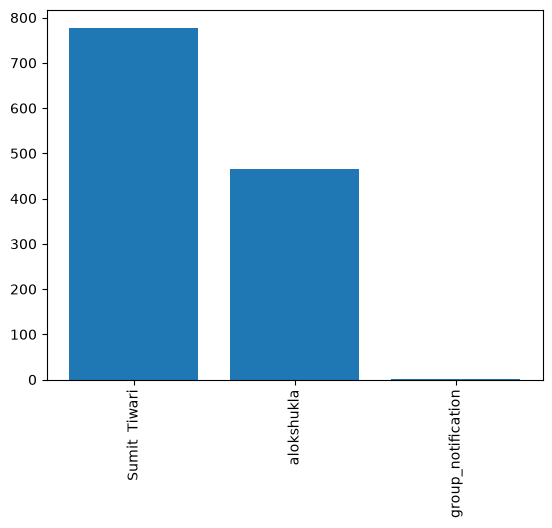

In [117]:
plt.bar(name,count)
plt.xticks(rotation='vertical')
plt.show()

In [126]:
round((df['user'].value_counts()/df.shape[0])*100,2).reset_index().rename(columns={'index':'name','user':'percent'})

,percent,count
0,Sumit Tiwari,62.49
1,alokshukla,37.35
2,group_notification,0.16


In [150]:
temp = df[df['user'] != 'group_notification']
temp = temp[temp['message'] != '<Media omitted>\n']

In [151]:
f = open('stop_hinglish.txt','r')
stop_words= f.read()
#print(stop_words)

In [152]:
words = []
for message in temp['message']:
    for word in message.lower().split():
        if word not in stop_words:
            words.append(word)

In [153]:
from collections import Counter
pd.DataFrame(Counter(words).most_common(20))

,0,1
0,yr,36
1,message,27
2,aba,25
3,gya,23
4,pta,16
5,<this,15
6,edited>,15
7,call,15
8,chandan,15
9,baat,13


In [160]:
!pip install emoji

In [161]:
import emoji

In [163]:
emojis = []

for message in df['message']:
    emojis.extend([c['emoji'] for c in emoji.emoji_list(str(message))])
    

In [165]:
pd.DataFrame(Counter(emojis).most_common(len(Counter(emojis))))

,0,1
0,😂,10
1,❤️,7
2,😀,6
3,😄,4
4,😁,4
5,🙏,3
6,🥹,3
7,🎈,3
8,😆,2
9,😊,2


In [172]:
df['date_num']=df['date'].dt.month

In [173]:
df


,date,user,message,only_date,year,month_num,month,day,day_name,hour,minute,date_num
0,2026-08-11 08:34:00,group_notification,Messages and calls are end-to-end encrypted. O...,2026-08-11,2026,8,August,11,Tuesday,8,34,8
1,2026-08-11 08:34:00,group_notification,Messages and calls are end-to-end encrypted. O...,2026-08-11,2026,8,August,11,Tuesday,8,34,8
2,2026-08-11 08:34:00,Sumit Tiwari,Aba\n,2026-08-11,2026,8,August,11,Tuesday,8,34,8
3,2026-08-11 08:34:00,Sumit Tiwari,Lag raha hai job mil gya hai\n,2026-08-11,2026,8,August,11,Tuesday,8,34,8
4,2026-08-11 08:34:00,Sumit Tiwari,Tabi itna busy ho gya 😀\n,2026-08-11,2026,8,August,11,Tuesday,8,34,8
...,...,...,...,...,...,...,...,...,...,...,...,...
1240,2026-10-31 11:06:00,alokshukla,Mast rho\n,2026-10-31,2026,10,October,31,Saturday,11,6,10
1241,2026-10-31 11:06:00,Sumit Tiwari,Acha\n,2026-10-31,2026,10,October,31,Saturday,11,6,10
1242,2026-10-31 11:06:00,Sumit Tiwari,Free hai?\n,2026-10-31,2026,10,October,31,Saturday,11,6,10
1243,2026-10-31 11:06:00,alokshukla,Evening me\n,2026-10-31,2026,10,October,31,Saturday,11,6,10


In [176]:
timeline = df.groupby(['year','date_num','month']).count()['message'].reset_index()

In [177]:
timeline

,year,date_num,month,message
0,2026,8,August,116
1,2026,9,September,621
2,2026,10,October,508


In [178]:
time = []

for i in range(timeline.shape[0]):
    time.append(timeline['month'][i] + "-" + str(timeline['year'][i]))

timeline['time'] = time

timeline

,year,date_num,month,message,time
0,2026,8,August,116,August-2026
1,2026,9,September,621,September-2026
2,2026,10,October,508,October-2026


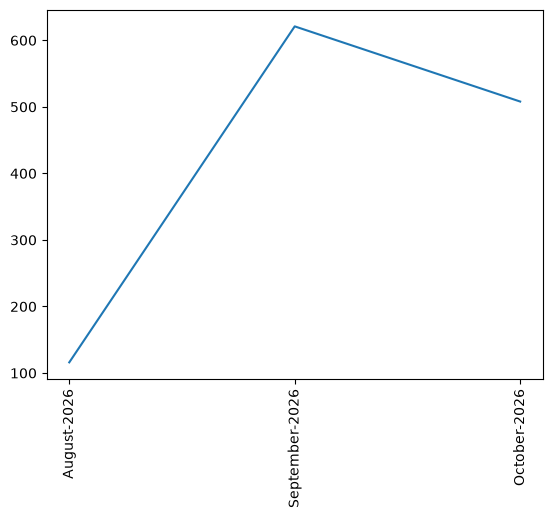

In [180]:
plt.plot(timeline['time'],timeline['message'])
plt.xticks(rotation ='vertical')
plt.show()

In [181]:
df['only_date'] = df['date'].dt.date

In [182]:
daily_timeline = df.groupby('only_date').count()['message'].reset_index()

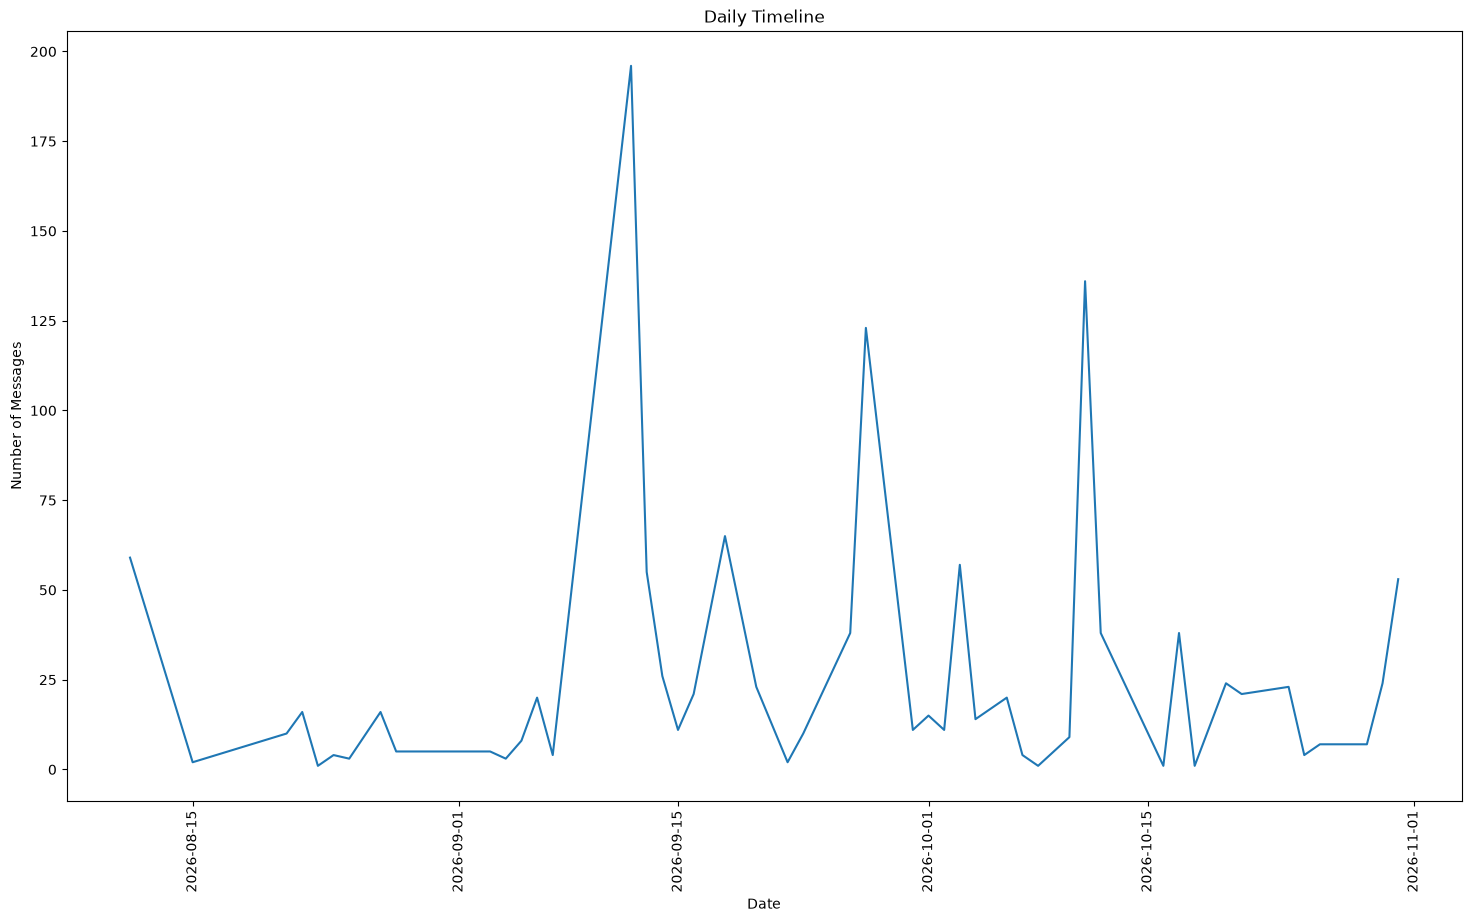

In [183]:
plt.figure(figsize=(18, 10))
plt.plot(daily_timeline['only_date'], daily_timeline['message'])
plt.xticks(rotation='vertical')
plt.xlabel('Date')
plt.ylabel('Number of Messages')
plt.title('Daily Timeline')
plt.show()

In [184]:
df['day_name'] = df['date'].dt.day_name()

In [185]:
df['day_name'].value_counts()

day_name
Saturday     440
Sunday       377
Tuesday      119
Friday       119
Monday        79
Wednesday     67
Thursday      44
Name: count, dtype: int64

In [186]:
period = []

for hour in df[['day_name', 'hour']]['hour']:
    if hour == 23:
        period.append(str(hour) + "-" + str('00'))
    elif hour == 0:
        period.append(str('00') + "-" + str(hour+1))
    else:
        period.append(str(hour) + "-" + str(hour+1))

In [187]:
df['period'] = period

In [188]:
df.sample(5)

,date,user,message,only_date,year,month_num,month,day,day_name,hour,minute,date_num,period
691,2026-09-27 18:54:00,alokshukla,Jaldi kro\n,2026-09-27,2026,9,September,27,Sunday,18,54,9,18-19
827,2026-10-04 05:42:00,Sumit Tiwari,<Media omitted>\n,2026-10-04,2026,10,October,4,Sunday,5,42,10,5-6
68,2026-08-21 12:08:00,alokshukla,Kya\n,2026-08-21,2026,8,August,21,Friday,12,8,8,12-13
70,2026-08-21 13:13:00,Sumit Tiwari,Aur credit card 💳 use kiya ?\n,2026-08-21,2026,8,August,21,Friday,13,13,8,13-14
430,2026-09-14 17:46:00,alokshukla,Acha\n,2026-09-14,2026,9,September,14,Monday,17,46,9,17-18


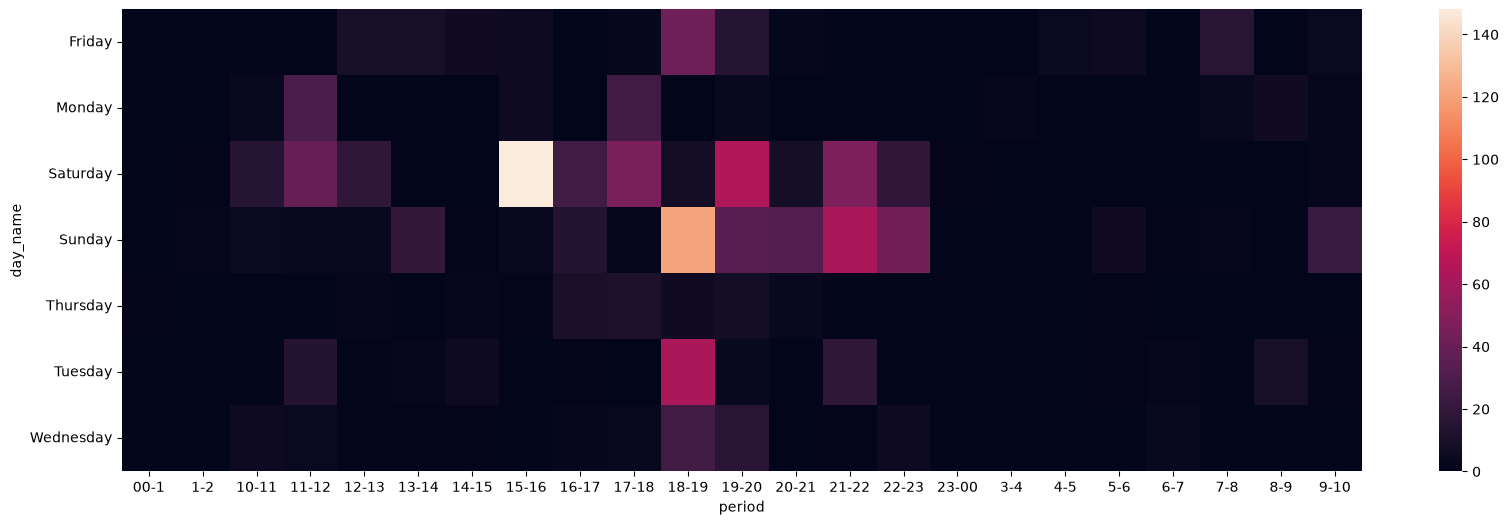

In [190]:
import seaborn as sns

plt.figure(figsize=(20, 6))

sns.heatmap(
    df.pivot_table(
        index='day_name',
        columns='period',
        values='message',
        aggfunc='count'
    ).fillna(0)
)

plt.yticks(rotation='horizontal')
plt.show()